# 🐝 BeeSafe AI — Notebook 03
## Data Preprocessing & Molecular Feature Engineering

**Goal:** Use the verified *Phase 02 audit output* and the original ApisTox dataset to build reproducible **structure-only ML features** without silently editing chemical identifiers, labels, or the raw CSV.


## Cell 1 — Imports and reproducibility settings
All required libraries were used in your previous notebooks. This notebook uses RDKit's modern **Morgan fingerprint generator**.

In [1]:
import os
import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, rdBase, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.info")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)

print("BeeSafe AI — Phase 03")
print("RDKit version:", rdBase.rdkitVersion)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

BeeSafe AI — Phase 03
RDKit version: 2026.09.1
NumPy version: 2.5.2
Pandas version: 3.0.5


## Cell 2 — Configure project folders and files
Same Windows E: drive location as Notebooks 01 and 02. You do not need a new Conda environment.

In [2]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_final.csv"
AUDIT_DIR = PROJECT_ROOT / "reports" / "chemical_identity_audit"
AUDIT_PATH = AUDIT_DIR / "02_full_chemical_identity_audit.csv"
AUDIT_SUMMARY_PATH = AUDIT_DIR / "02_audit_summary.json"
VERIFICATION_PATH = AUDIT_DIR / "02_automated_pubchem_verification.csv"

OUT_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
REPORT_DIR = PROJECT_ROOT / "reports" / "feature_engineering"
FIG_DIR = REPORT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Configuration: do not silently change these after analyzing test results.
MORGAN_RADIUS = 2
MORGAN_BITS = 2048
INCLUDE_CHIRALITY = False
BASELINE_POLICY = "WITHHOLD_ALL_PHASE02_REVIEW_PRIORITY_NON_NONE"

for path, description in [
    (RAW_PATH, "Original ApisTox CSV"),
    (AUDIT_PATH, "Notebook 02 full audit report"),
    (AUDIT_SUMMARY_PATH, "Notebook 02 audit summary"),
]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {description}: {path}\n"
            "Run the automated Phase 02 notebook and save its outputs first."
        )

print("Project:", PROJECT_ROOT)
print("Original CSV:", RAW_PATH)
print("Phase 02 audit:", AUDIT_PATH)
print("Output folder:", OUT_DIR)

Project: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Original CSV: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\raw\dataset_final.csv
Phase 02 audit: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\chemical_identity_audit\02_full_chemical_identity_audit.csv
Output folder: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03


## Cell 3 — Load the raw dataset and verify its SHA-256 against Phase 02
This is a reproducibility check: if the original CSV has changed since Phase 02, **stop and rerun Phase 02** rather than silently relying on an outdated audit.

In [3]:
raw_sha256_before = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(RAW_PATH)
audit = pd.read_csv(AUDIT_PATH)
with open(AUDIT_SUMMARY_PATH, "r", encoding="utf-8") as fh:
    phase02_summary = json.load(fh)

expected_sha = phase02_summary.get("source_csv_sha256")
if not expected_sha:
    raise ValueError("Phase 02 summary has no source_csv_sha256. Rerun Phase 02.")
if raw_sha256_before != expected_sha:
    raise ValueError(
        "Original dataset SHA-256 differs from Phase 02! "
        "Rerun Phase 02 before continuing."
    )

required_raw = {"name", "CID", "CAS", "SMILES", "source", "label", "ppdb_level"}
required_audit = {
    "source_row_index", "review_priority", "SMILES", "CID", "label"
}
if required_raw - set(raw.columns):
    raise ValueError(f"Raw CSV missing: {sorted(required_raw - set(raw.columns))}")
if required_audit - set(audit.columns):
    raise ValueError(f"Phase 02 audit missing: {sorted(required_audit - set(audit.columns))}")
if raw.empty:
    raise ValueError("Source dataset is empty")

print("Raw dataset:", raw.shape)
print("Phase 02 audit:", audit.shape)
print("Source checksum verified:", raw_sha256_before == expected_sha)
print("Original class counts:", raw["label"].value_counts(dropna=False).to_dict())
display(raw.head(3))

Raw dataset: (1035, 13)
Phase 02 audit: (1035, 30)
Source checksum verified: True
Original class counts: {0: 739, 1: 296}


,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0


## Cell 4 — Align Phase 02 results with the exact original CSV rows
Use a stable **`source_row_index`** (0-based) to avoid ambiguous joins on duplicated CIDs. A PubChem match here is **not** considered verification of a toxicity label.

In [4]:
audit = audit.copy()
audit["source_row_index"] = pd.to_numeric(
    audit["source_row_index"], errors="raise"
).astype(int)

expected_indices = set(range(len(raw)))
actual_indices = set(audit["source_row_index"].tolist())
if len(audit) != len(raw) or len(actual_indices) != len(audit) or actual_indices != expected_indices:
    raise ValueError("Phase 02 audit row indices do not exactly match the raw dataset")

audit = audit.sort_values("source_row_index").reset_index(drop=True)
for col in ["SMILES", "CID", "label"]:
    if not (raw[col].astype(str).to_numpy() == audit[col].astype(str).to_numpy()).all():
        raise ValueError(f"Phase 02 audit differs from original CSV in {col}!")

metadata = raw.copy(deep=True)
metadata.insert(0, "source_row_index", np.arange(len(raw), dtype=int))
metadata["review_priority"] = audit["review_priority"].fillna("UNKNOWN").astype(str).to_numpy()
metadata["phase02_issue_flags"] = (
    audit["issue_flags"].fillna("").astype(str).to_numpy()
    if "issue_flags" in audit.columns else ""
)

# Verification results are evidence about identity, never automatic label edits.
metadata["pubchem_verification_status"] = "NOT_FLAGGED_FOR_LOOKUP"
if VERIFICATION_PATH.exists():
    verification = pd.read_csv(VERIFICATION_PATH)
    if {"source_row_index", "verification_status"}.issubset(verification.columns):
        if verification["source_row_index"].duplicated().any():
            raise ValueError("Duplicate source_row_index in Phase 02 PubChem verification")
        ver_map = verification.set_index("source_row_index")["verification_status"]
        metadata["pubchem_verification_status"] = (
            metadata["source_row_index"].map(ver_map)
            .fillna("NOT_FLAGGED_FOR_LOOKUP")
        )
else:
    print("NOTE: PubChem verification CSV missing; using audit review flags only.")

print("Review priority distribution:")
display(metadata["review_priority"].value_counts(dropna=False).to_frame("Records"))
print("Automated PubChem statuses:")
display(metadata["pubchem_verification_status"].value_counts().to_frame("Records"))

Review priority distribution:


,Records
review_priority,
NONE,1025
MEDIUM,6
HIGH,4


Automated PubChem statuses:


,Records
pubchem_verification_status,
NOT_FLAGGED_FOR_LOOKUP,1025
ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,4
CID_AND_STRUCTURE_MATCH_PUBCHEM,4
RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,2


## Cell 5 — Canonical SMILES, largest-fragment identity, and scaffold grouping
For **features**, use the **full original molecule** (including any counterions), not a guessed corrected structure. For **leakage-aware grouping**, use the largest fragment and its Bemis–Murcko scaffold. For acyclic molecules (empty scaffold), use the fragment identity as fallback. Grouping is only *prepared* now; train/test splitting is Phase 04.

In [5]:
def largest_fragment(mol):
    fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    if not fragments:
        return mol
    return max(
        fragments,
        key=lambda m: (m.GetNumHeavyAtoms(), Chem.MolToSmiles(m, canonical=True))
    )

def make_structure_metadata(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return (False, None, None, None, None, "MISSING_SMILES")
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return (False, None, None, None, None, "INVALID_SMILES")
        canonical = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
        core = largest_fragment(mol)
        core_str = Chem.MolToSmiles(core, canonical=True, isomericSmiles=True)
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=core, includeChirality=False)
        # Explicit acyclic fallback avoids grouping every acyclic molecule together.
        grouping = "SCAFFOLD:" + scaffold if scaffold else "ACYCLIC:" + core_str
        return (True, canonical, core_str, scaffold, grouping, "VALID")
    except Exception as exc:
        return (False, None, None, None, None, f"PARSING_ERROR:{type(exc).__name__}")

structure_rows = [make_structure_metadata(s) for s in raw["SMILES"]]
structure_cols = [
    "smiles_valid", "canonical_smiles", "largest_fragment_smiles",
    "murcko_scaffold", "structure_group", "structure_parse_status"
]
structure_df = pd.DataFrame(structure_rows, columns=structure_cols)
for col in structure_cols:
    metadata[col] = structure_df[col].to_numpy()

print("RDKit-valid SMILES:", int(metadata["smiles_valid"].sum()), "/", len(metadata))
print("Unique full canonical structures:", metadata["canonical_smiles"].nunique())
print("Unique scaffold/fallback grouping keys:", metadata["structure_group"].nunique())
print("Acyclic molecules:", int(metadata["murcko_scaffold"].eq("").sum()))
display(metadata[["name", "SMILES", "canonical_smiles", "structure_group"]].head())

RDKit-valid SMILES: 1035 / 1035
Unique full canonical structures: 1035
Unique scaffold/fallback grouping keys: 572
Acyclic molecules: 186


,name,SMILES,canonical_smiles,structure_group
0,Ethanedioic acid,O=C(O)C(=O)O,O=C(O)C(=O)O,ACYCLIC:O=C(O)C(=O)O
1,Para-cymene,Cc1ccc(C(C)C)cc1,Cc1ccc(C(C)C)cc1,SCAFFOLD:c1ccccc1
2,Kieselguhr,O=[Si]=O,O=[Si]=O,ACYCLIC:O=[Si]=O
3,Benzoic acid,O=C(O)c1ccccc1,O=C(O)c1ccccc1,SCAFFOLD:c1ccccc1
4,Tetradifon (Ref: ENT 23737),O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1


## Cell 6 — Generate 12 interpretable RDKit molecular descriptors
This is **feature extraction**, not model training. Missing descriptor values (if any) will be excluded from the conservative baseline, with reasons retained. The features do **not** include `label`, `ppdb_level`, CID, name, CAS, source, year, or toxicity type.

In [6]:
DESCRIPTOR_NAMES = [
    "MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors",
    "RingCount", "HeavyAtomCount", "NumRotatableBonds",
    "NumAromaticRings", "FractionCSP3", "FormalCharge", "NumHeteroatoms"
]

def get_descriptors(mol):
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.TPSA(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol),
        rdMolDescriptors.CalcNumRings(mol),
        mol.GetNumHeavyAtoms(),
        Descriptors.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        rdMolDescriptors.CalcFractionCSP3(mol),
        Chem.GetFormalCharge(mol),
        Descriptors.NumHeteroatoms(mol),
    ]

X_desc_all = np.full((len(raw), len(DESCRIPTOR_NAMES)), np.nan, dtype=np.float64)
parsed_mols = []
for idx, smiles in enumerate(raw["SMILES"]):
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles.strip() else None
    parsed_mols.append(mol)
    if mol is not None:
        try:
            X_desc_all[idx] = get_descriptors(mol)
        except Exception as exc:
            print(f"Descriptor calculation failed for source_row_index {idx}: {exc}")

metadata["descriptors_finite"] = np.isfinite(X_desc_all).all(axis=1)
desc_table_all = pd.DataFrame(X_desc_all, columns=DESCRIPTOR_NAMES)
desc_table_all.insert(0, "source_row_index", metadata["source_row_index"].to_numpy())

print("Descriptor matrix (all rows):", X_desc_all.shape)
print("Rows with finite descriptors:", int(metadata["descriptors_finite"].sum()))
print("Feature names:", DESCRIPTOR_NAMES)
display(desc_table_all.head())
display(desc_table_all[DESCRIPTOR_NAMES].describe().T.round(3))

Descriptor matrix (all rows): (1035, 12)
Rows with finite descriptors: 1035
Feature names: ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'RingCount', 'HeavyAtomCount', 'NumRotatableBonds', 'NumAromaticRings', 'FractionCSP3', 'FormalCharge', 'NumHeteroatoms']


,source_row_index,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,RingCount,HeavyAtomCount,NumRotatableBonds,NumAromaticRings,FractionCSP3,FormalCharge,NumHeteroatoms
0,0,90.034,-0.84440,74.60,2.0,2.0,0.0,6.0,0.0,0.0,0.0,0.0,4.0
1,1,134.222,3.11842,0.00,0.0,0.0,1.0,10.0,1.0,1.0,0.4,0.0,0.0
2,2,60.084,-0.61840,34.14,0.0,2.0,0.0,3.0,0.0,0.0,0.0,0.0,3.0
3,3,122.123,1.38480,37.30,1.0,1.0,1.0,9.0,1.0,1.0,0.0,0.0,2.0
4,4,356.057,5.13300,34.14,0.0,2.0,2.0,19.0,2.0,2.0,0.0,0.0,7.0


,count,mean,std,min,25%,50%,75%,max
MolWt,1035.0,319.782,151.767,32.067,229.715,310.297,379.960,1732.153
MolLogP,1035.0,2.496,3.096,-20.533,1.426,2.876,4.190,19.786
TPSA,1035.0,67.046,60.569,0.000,36.920,55.840,80.275,896.660
NumHDonors,1035.0,0.933,1.880,0.000,0.000,0.000,1.000,30.000
NumHAcceptors,1035.0,4.214,3.285,0.000,2.000,4.000,5.000,47.000
RingCount,1035.0,1.724,1.438,0.000,1.000,2.000,2.000,15.000
HeavyAtomCount,1035.0,20.313,10.333,1.000,14.000,20.000,25.000,123.000
NumRotatableBonds,1035.0,4.395,3.264,0.000,2.000,4.000,6.000,26.000
NumAromaticRings,1035.0,1.234,1.029,0.000,0.000,1.000,2.000,8.000
FractionCSP3,1035.0,0.406,0.286,0.000,0.200,0.357,0.588,1.000


## Cell 7 — Generate 2048-bit radius-2 Morgan fingerprints (ECFP-like)
Each bit represents the presence of a hashed local chemical environment. The fingerprint is computed from the original **full SMILES**; `Morgan radius = 2`, `2048 bits`, `chirality = False` are recorded in the manifest. No toxicity labels enter this calculation.

In [7]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS,
    fpSize=MORGAN_BITS,
    includeChirality=INCLUDE_CHIRALITY
)

X_fp_all = np.zeros((len(raw), MORGAN_BITS), dtype=np.uint8)
for idx, mol in enumerate(parsed_mols):
    if mol is None:
        continue
    try:
        rdkit_fp = morgan_generator.GetFingerprint(mol)
        fp_array = np.zeros(MORGAN_BITS, dtype=np.int32)
        DataStructs.ConvertToNumpyArray(rdkit_fp, fp_array)
        X_fp_all[idx] = fp_array.astype(np.uint8)
    except Exception as exc:
        print(f"Fingerprint failed for source_row_index {idx}: {exc}")

metadata["fingerprint_nonzero_bits"] = X_fp_all.sum(axis=1).astype(int)
metadata["fingerprint_valid"] = metadata["smiles_valid"] & (
    metadata["fingerprint_nonzero_bits"] > 0
)

print("Morgan fingerprint matrix:", X_fp_all.shape)
print("Array datatype:", X_fp_all.dtype)
print("Total active bits:", int(X_fp_all.sum()))
print("Rows with non-empty fingerprints:", int(metadata["fingerprint_valid"].sum()))
assert set(np.unique(X_fp_all)).issubset({0, 1}), "Morgan fingerprint must be binary"

Morgan fingerprint matrix: (1035, 2048)
Array datatype: uint8
Total active bits: 35048
Rows with non-empty fingerprints: 1035


## Cell 8 — Determine baseline eligibility transparently
**Conservative rule:** withhold *all* flagged Phase 02 records, including PubChem-matched members of a problematic pair. This protects the first baseline from unresolved identity issues without claiming those records are toxic or invalid. Keep an export of excluded rows for later sensitivity analysis. The label column is checked but **never modified**.

In [8]:
labels_numeric = pd.to_numeric(metadata["label"], errors="coerce")
metadata["binary_label_valid"] = labels_numeric.isin([0, 1])

metadata["baseline_eligible"] = (
    metadata["review_priority"].eq("NONE")
    & metadata["smiles_valid"]
    & metadata["descriptors_finite"]
    & metadata["fingerprint_valid"]
    & metadata["binary_label_valid"]
)

def exclusion_reason(row):
    reasons = []
    if row["review_priority"] != "NONE":
        reasons.append("PHASE02_IDENTITY_REVIEW")
    if not row["smiles_valid"]:
        reasons.append("INVALID_OR_MISSING_SMILES")
    if not row["descriptors_finite"]:
        reasons.append("DESCRIPTOR_NOT_FINITE")
    if not row["fingerprint_valid"]:
        reasons.append("FINGERPRINT_NOT_VALID")
    if not row["binary_label_valid"]:
        reasons.append("LABEL_NOT_0_OR_1")
    return ";".join(reasons) if reasons else "INCLUDED"

metadata["baseline_decision_reason"] = metadata.apply(exclusion_reason, axis=1)
keep_mask = metadata["baseline_eligible"].to_numpy(dtype=bool)
model_metadata = metadata.loc[keep_mask].reset_index(drop=True).copy()
excluded_metadata = metadata.loc[~keep_mask].reset_index(drop=True).copy()

X_desc = X_desc_all[keep_mask].copy()
X_fp = X_fp_all[keep_mask].copy()
y = labels_numeric.loc[keep_mask].to_numpy(dtype=np.int64)
row_ids = metadata.loc[keep_mask, "source_row_index"].to_numpy(dtype=np.int64)

print("Conservative baseline records:", len(model_metadata))
print("Withheld from baseline:", len(excluded_metadata))
print("Baseline label distribution:", dict(pd.Series(y).value_counts().sort_index()))
print("Reasons for withholding:")
display(excluded_metadata["baseline_decision_reason"].value_counts().to_frame("Records"))
display(excluded_metadata[[
    "source_row_index", "name", "CID", "label", "review_priority",
    "pubchem_verification_status", "baseline_decision_reason"
]].head(15))

Conservative baseline records: 1025
Withheld from baseline: 10
Baseline label distribution: {0: np.int64(731), 1: np.int64(294)}
Reasons for withholding:


,Records
baseline_decision_reason,
PHASE02_IDENTITY_REVIEW,10


,source_row_index,name,CID,label,review_priority,pubchem_verification_status,baseline_decision_reason
0,290,Chlormequat,13836,0,MEDIUM,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,PHASE02_IDENTITY_REVIEW
1,295,"2-Chloro-N,N,N-trimethylethanaminium chloride ...",13836,0,MEDIUM,CID_AND_STRUCTURE_MATCH_PUBCHEM,PHASE02_IDENTITY_REVIEW
2,323,Metiram (Ref: BAS 222F),5284484,0,HIGH,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,PHASE02_IDENTITY_REVIEW
3,328,Zineb (Ref: ENT 14874),5284484,1,HIGH,CID_AND_STRUCTURE_MATCH_PUBCHEM,PHASE02_IDENTITY_REVIEW
4,413,Silthiofam (Ref: MON 65500),16116,0,MEDIUM,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,PHASE02_IDENTITY_REVIEW
5,416,N-(2-Methylcyclohexyl)-N'-phenylurea,16116,0,MEDIUM,CID_AND_STRUCTURE_MATCH_PUBCHEM,PHASE02_IDENTITY_REVIEW
6,670,Diclomezine (Ref: F-850),93341,0,HIGH,CID_AND_STRUCTURE_MATCH_PUBCHEM,PHASE02_IDENTITY_REVIEW
7,672,Diflumetorim (Ref: UBF 002),93341,1,HIGH,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,PHASE02_IDENTITY_REVIEW
8,824,Metominostrobin (Ref: SSF 126),5483872,0,MEDIUM,RECORDED_CID_STRUCTURE_MISMATCH_REVIEW,PHASE02_IDENTITY_REVIEW
9,832,Phthalide (Ref: BAY 96610),5483872,0,MEDIUM,ALTERNATE_CID_STRUCTURE_MATCH_REVIEW,PHASE02_IDENTITY_REVIEW


## Cell 9 — Check descriptor quality and fingerprint coverage on the baseline
**No imputation, normalization, feature selection or class balancing now**: they must be fitted on the *training fold only* during Phase 04. These are descriptive checks, not feature selection.

In [9]:
if len(model_metadata) == 0:
    raise ValueError("No eligible baseline records; review audit and preprocessing rules")

assert np.isfinite(X_desc).all(), "Baseline descriptors contain NaN or infinity"
assert np.isin(y, [0, 1]).all(), "Unexpected labels in baseline"
assert X_fp.shape == (len(y), MORGAN_BITS)
assert X_desc.shape == (len(y), len(DESCRIPTOR_NAMES))
assert not np.any(X_fp.sum(axis=1) == 0), "Unexpected empty fingerprints"

fp_bit_frequency = X_fp.mean(axis=0)
nonconstant_fp_bits = int(np.count_nonzero((fp_bit_frequency > 0) & (fp_bit_frequency < 1)))
constant_zero_fp_bits = int(np.count_nonzero(fp_bit_frequency == 0))
constant_one_fp_bits = int(np.count_nonzero(fp_bit_frequency == 1))

print("Model dataset sizes:")
print("X_desc:", X_desc.shape)
print("X_fp:", X_fp.shape)
print("y:", y.shape)
print("Nonconstant fingerprint bits:", nonconstant_fp_bits)
print("Always-zero fingerprint bits:", constant_zero_fp_bits)
print("Always-one fingerprint bits:", constant_one_fp_bits)
print("Unique structure groups:", model_metadata["structure_group"].nunique())

baseline_descriptor_stats = pd.DataFrame(X_desc, columns=DESCRIPTOR_NAMES).describe().T
print("Descriptor statistics for eligible records:")
display(baseline_descriptor_stats.round(3))

Model dataset sizes:
X_desc: (1025, 12)
X_fp: (1025, 2048)
y: (1025,)
Nonconstant fingerprint bits: 1971
Always-zero fingerprint bits: 77
Always-one fingerprint bits: 0
Unique structure groups: 566
Descriptor statistics for eligible records:


,count,mean,std,min,25%,50%,75%,max
MolWt,1025.0,320.268,152.124,32.067,229.715,311.341,380.784,1732.153
MolLogP,1025.0,2.501,3.105,-20.533,1.436,2.880,4.198,19.786
TPSA,1025.0,67.354,60.737,0.000,37.300,56.270,80.320,896.660
NumHDonors,1025.0,0.929,1.882,0.000,0.000,0.000,1.000,30.000
NumHAcceptors,1025.0,4.230,3.291,0.000,2.000,4.000,5.000,47.000
RingCount,1025.0,1.730,1.441,0.000,1.000,2.000,2.000,15.000
HeavyAtomCount,1025.0,20.360,10.360,1.000,14.000,20.000,25.000,123.000
NumRotatableBonds,1025.0,4.408,3.271,0.000,2.000,4.000,6.000,26.000
NumAromaticRings,1025.0,1.237,1.030,0.000,0.000,1.000,2.000,8.000
FractionCSP3,1025.0,0.405,0.285,0.000,0.200,0.357,0.588,1.000


## Cell 10 — Visual QC figures
Class distribution after conservative filtering and molecular fingerprint density. These are descriptive figures; no training happens here.

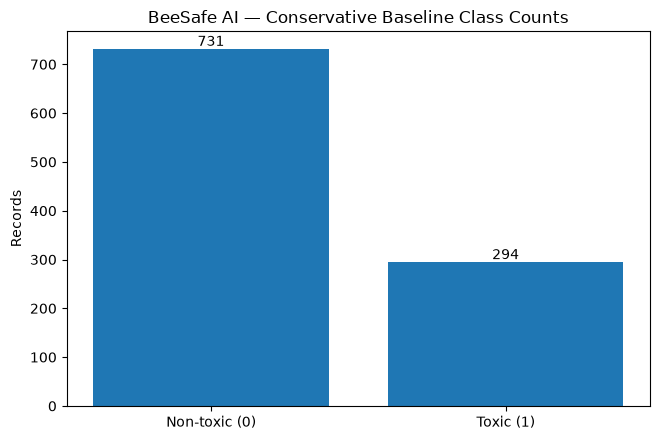

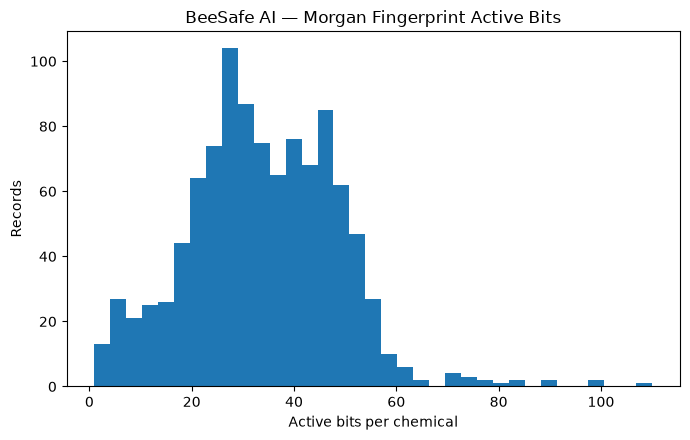

In [10]:
fig, ax = plt.subplots(figsize=(6.7, 4.5))
labels_count = pd.Series(y).value_counts().reindex([0, 1], fill_value=0)
bars = ax.bar(["Non-toxic (0)", "Toxic (1)"], labels_count.values)
ax.bar_label(bars)
ax.set_title("BeeSafe AI — Conservative Baseline Class Counts")
ax.set_ylabel("Records")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_baseline_class_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(X_fp.sum(axis=1), bins=35)
ax.set_title("BeeSafe AI — Morgan Fingerprint Active Bits")
ax.set_xlabel("Active bits per chemical")
ax.set_ylabel("Records")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fingerprint_density.png", dpi=220, bbox_inches="tight")
plt.show()

## Cell 11 — Save ML-ready matrices and metadata
**Primary artifact:** `03_baseline_features.npz`, with `X_descriptors`, `X_morgan`, `y_binary`, `source_row_index`, descriptor names. Arrays share **exactly the same row order** as `03_baseline_metadata.csv`.

**Sensitivity artifact:** `03_all_records_features.npz` includes all original records; invalid structures (if any) have `NaN` descriptors/zero fingerprints and must be filtered before modeling. **Do not accidentally train on this file without a documented decision.**

In [11]:
from numpy.lib.format import open_memmap

baseline_npz_path = OUT_DIR / "03_baseline_features.npz"
all_npz_path = OUT_DIR / "03_all_records_features.npz"

np.savez_compressed(
    baseline_npz_path,
    X_descriptors=X_desc,
    X_morgan=X_fp,
    y_binary=y,
    source_row_index=row_ids,
    descriptor_names=np.array(DESCRIPTOR_NAMES, dtype=str),
)
np.savez_compressed(
    all_npz_path,
    X_descriptors=X_desc_all,
    X_morgan=X_fp_all,
    y_binary=labels_numeric.to_numpy(dtype=np.float64),
    source_row_index=metadata["source_row_index"].to_numpy(dtype=np.int64),
    descriptor_names=np.array(DESCRIPTOR_NAMES, dtype=str),
)

metadata.to_csv(OUT_DIR / "03_all_record_metadata.csv", index=False, encoding="utf-8-sig")
model_metadata.to_csv(OUT_DIR / "03_baseline_metadata.csv", index=False, encoding="utf-8-sig")
excluded_metadata.to_csv(OUT_DIR / "03_withheld_review_records.csv", index=False, encoding="utf-8-sig")
desc_table_all.to_csv(OUT_DIR / "03_all_descriptor_features.csv", index=False, encoding="utf-8-sig")

pd.DataFrame(X_desc, columns=DESCRIPTOR_NAMES).assign(
    source_row_index=row_ids
).to_csv(OUT_DIR / "03_baseline_descriptor_features.csv", index=False, encoding="utf-8-sig")

baseline_descriptor_stats.round(5).to_csv(
    REPORT_DIR / "03_baseline_descriptor_summary.csv", encoding="utf-8-sig"
)

print("Saved baseline ML arrays:", baseline_npz_path)
print("Saved all-record arrays:", all_npz_path)
print("Saved baseline metadata:", OUT_DIR / "03_baseline_metadata.csv")
print("Saved withheld records:", OUT_DIR / "03_withheld_review_records.csv")

Saved baseline ML arrays: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_baseline_features.npz
Saved all-record arrays: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_all_records_features.npz
Saved baseline metadata: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_baseline_metadata.csv
Saved withheld records: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03\03_withheld_review_records.csv


## Cell 12 — Create a reproducibility manifest
The manifest records the raw-data checksum, audit policy, descriptor order, and fingerprint settings. **No post hoc change to feature definitions after seeing model test performance.**

In [12]:
manifest = {
    "project": "BeeSafe AI",
    "phase": "03_data_preprocessing_and_feature_engineering",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "raw_data_sha256": raw_sha256_before,
    "phase02_source_csv_sha256": expected_sha,
    "raw_rows": int(len(raw)),
    "phase02_flagged_rows": int(metadata["review_priority"].ne("NONE").sum()),
    "conservative_baseline_rows": int(len(model_metadata)),
    "withheld_rows": int(len(excluded_metadata)),
    "baseline_policy": BASELINE_POLICY,
    "no_cid_cas_smiles_or_label_corrected": True,
    "morgan": {
        "algorithm": "RDKit Morgan bit vector (ECFP-like)",
        "radius": MORGAN_RADIUS,
        "n_bits": MORGAN_BITS,
        "include_chirality": INCLUDE_CHIRALITY,
        "molecule_representation": "original full SMILES including counterions"
    },
    "descriptor_names_in_column_order": DESCRIPTOR_NAMES,
    "model_inputs_excluded": [
        "name", "CID", "CAS", "source", "year", "toxicity_type",
        "label", "ppdb_level", "pubchem_verification_status", "review_priority"
    ],
    "target_column": "label",
    "positive_class": 1,
    "structure_group": "Bemis-Murcko scaffold of largest fragment; acyclic fallback to largest fragment canonical SMILES",
    "splitting_done": False,
    "model_training_done": False,
    "rdkit_version": rdBase.rdkitVersion,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "output_files": sorted(p.name for p in OUT_DIR.iterdir() if p.is_file()),
}

manifest_path = REPORT_DIR / "03_feature_manifest.json"
with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("Manifest saved:", manifest_path)
print("Summary:")
print(json.dumps({k: manifest[k] for k in (
    "raw_rows", "phase02_flagged_rows", "conservative_baseline_rows",
    "withheld_rows", "splitting_done", "model_training_done"
)}, indent=2))

Manifest saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\feature_engineering\03_feature_manifest.json
Summary:
{
  "raw_rows": 1035,
  "phase02_flagged_rows": 10,
  "conservative_baseline_rows": 1025,
  "withheld_rows": 10,
  "splitting_done": false,
  "model_training_done": false
}


## Cell 13 — Reload saved matrices and perform final integrity checks
Fail loudly if file alignment, array shape, fingerprint type, labels, or source checksum is wrong.

In [13]:
with np.load(baseline_npz_path, allow_pickle=False) as saved:
    reloaded_X = saved["X_descriptors"]
    reloaded_fp = saved["X_morgan"]
    reloaded_y = saved["y_binary"]
    reloaded_rows = saved["source_row_index"]
    reloaded_features = saved["descriptor_names"].tolist()

reloaded_metadata = pd.read_csv(OUT_DIR / "03_baseline_metadata.csv")

assert np.array_equal(reloaded_X, X_desc), "Descriptor data changed after saving"
assert np.array_equal(reloaded_fp, X_fp), "Fingerprints changed after saving"
assert np.array_equal(reloaded_y, y), "Labels changed after saving"
assert np.array_equal(reloaded_rows, row_ids), "Row ordering changed after saving"
assert reloaded_features == DESCRIPTOR_NAMES, "Descriptor order changed after saving"
assert np.array_equal(reloaded_rows, reloaded_metadata["source_row_index"].to_numpy()), "Metadata misaligned"
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == raw_sha256_before, "Original dataset modified!"
assert len(model_metadata) + len(excluded_metadata) == len(raw)
assert set(model_metadata["review_priority"]) == {"NONE"}
assert np.array_equal(reloaded_y, reloaded_metadata["label"].to_numpy(dtype=np.int64))

print("=" * 65)
print("BEESAFE AI — PHASE 03 FEATURE ENGINEERING COMPLETE")
print("=" * 65)
print("Original CSV unchanged: True")
print("Phase 02 checksum matched: True")
print("Source records:", len(raw))
print("Conservative baseline records:", len(model_metadata))
print("Withheld from first baseline:", len(excluded_metadata))
print("Descriptor matrix:", X_desc.shape)
print("Morgan fingerprint matrix:", X_fp.shape)
print("Baseline labels:", dict(pd.Series(y).value_counts().sort_index()))
print("Outputs:", OUT_DIR)
print("Next notebook: 04_baseline_model_training_and_evaluation.ipynb")

BEESAFE AI — PHASE 03 FEATURE ENGINEERING COMPLETE
Original CSV unchanged: True
Phase 02 checksum matched: True
Source records: 1035
Conservative baseline records: 1025
Withheld from first baseline: 10
Descriptor matrix: (1025, 12)
Morgan fingerprint matrix: (1025, 2048)
Baseline labels: {0: np.int64(731), 1: np.int64(294)}
Outputs: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\data\processed\phase03
Next notebook: 04_baseline_model_training_and_evaluation.ipynb


---
## Interpretation / what is NOT done in Phase 03

- **No ML model has been trained**; `03_baseline_features.npz` is a prepared data artifact, not a model.
- **No automatic correction** of chemical CID, name, structure, CAS, or toxicity label.
- **No train/test split, standardization, oversampling/SMOTE, or tuning**: those steps belong to Phase 04, so training data statistics cannot leak into test results.
- **Scaffold groups are proxies** for molecular relatedness, not a guarantee of completely independent chemistry. Phase 04 should compare scaffold-aware and random split (if desired), prefer official ApisTox evaluation splits where applicable, and report the protocol.
- **PubChem validates identity, not experimental bee-toxicity outcome.** These are screening predictions, not claims of real-world pesticide safety.
- **Publication caution:** avoid pushing `data/raw` or generated compound-level data to a public GitHub repository until ApisTox redistribution terms are checked. Code, figures, and an environment specification are usually safer portfolio materials.